In [2]:
import sys
import pandas as pd
import numpy as np 
print("Python executable:", sys.executable)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Python executable: d:\kidney-disease-analytics\.venv\Scripts\python.exe
Pandas version: 3.0.6
NumPy version: 2.5.4



### Data Cleaning Note: SAS Floating-Point Artifacts

**Issue identified:** The minimum value of `RIDAGEYR` was approximately `5.397605e-79`,  which is unusually small for an age measurement recorded in years and requires further investigation.
**Investigation:** The observed value was examined as a potential data-import or floating-point representation issue. NHANES also permits an age value of zero for participants younger than one year. Therefore, valid zero-age observations must be preserved during data cleaning.

**Correction approach:**  Extremely small numeric values will not be replaced globally without verification. Each affected variable will be inspected to determine whether the value represents a true zero or an import-related artefact. Corrections will only be applied when supported by verification.



**Correction applied:** No blanket replacement of extremely small numeric values is applied at this stage. The original imported values are retained until their meaning is verified.
**Scope of the correction:**
- The investigation is performed on the loaded DataFrames in memory.
- The original `.xpt` files in data/raw/ remain unchanged.
- he threshold of **1e-70** is used only to identify potentially unusual values for inspection, not as an automatic correction rule.
- Other missing-value codes and potentially invalid measurements will be examined separately using the official NHANES documentation

**Validation:**  The age distribution is inspected using descriptive statistics, including minimum, maximum, missing-value count, and exact-zero count. The adult study population is subsequently identified using  `RIDAGEYR` >= 20.
**Limitation:** Identifying an extremely small numeric value does not establish its original meaning. Any correction requires verification against the source data and relevant NHANES documentation.


In [3]:

import pandas as pd
from pathlib import Path

raw_dir = Path("../data/raw")

expected = {
    "P_DEMO": ["SEQN", "RIDAGEYR", "RIAGENDR", "RIDRETH3",
               "RIDEXPRG", "INDFMPIR", "WTMECPRP", "SDMVPSU", "SDMVSTRA"],
    "P_DIQ": ["SEQN", "DIQ010", "DIQ050", "DIQ070"],
    "P_GHB": ["SEQN", "LBXGH"],
    "P_BIOPRO": ["SEQN", "LBXSCR"],
    "P_ALB_CR": ["SEQN", "URXUMA", "URXUCR", "URDACT"],
    "P_BMX": ["SEQN", "BMXBMI", "BMXWAIST"],
    "P_BPXO": ["SEQN", "BPXOSY1", "BPXODI1"],
    "P_SMQ": ["SEQN", "SMQ020", "SMQ040"],
}

rows = []
tables = {}

for name, wanted in expected.items():
    path = raw_dir / f"{name}.xpt"

    if not path.exists():
        rows.append({
            "file": name,
            "rows": None,
            "cols": None,
            "seqn_unique": None,
            "missing_vars": "FILE NOT FOUND",
        })
        continue

    df = pd.read_sas(path, format="xport")
    tables[name] = df

    missing = [v for v in wanted if v not in df.columns]

    rows.append({
        "file": name,
        "rows": df.shape[0],
        "cols": df.shape[1],
        "seqn_unique": (
            df["SEQN"].is_unique if "SEQN" in df.columns else None
        ),
        "missing_vars": missing,
    })

audit = pd.DataFrame(rows)
display(audit)


,file,rows,cols,seqn_unique,missing_vars
0,P_DEMO,15560,29,True,[]
1,P_DIQ,14986,28,True,[]
2,P_GHB,10409,2,True,[]
3,P_BIOPRO,10409,41,True,[]
4,P_ALB_CR,13027,8,True,[]
5,P_BMX,14300,22,True,[]
6,P_BPXO,11656,12,True,[]
7,P_SMQ,11137,16,True,[]


In [4]:
tables["P_DEMO"][["SEQN", "RIDAGEYR"]].describe()

,SEQN,RIDAGEYR
count,15560.00000,1.556000e+04
mean,117042.50000,3.374248e+01
std,4491.92943,2.532053e+01
min,109263.00000,5.397605e-79
25%,113152.75000,1.000000e+01
50%,117042.50000,3.000000e+01
75%,120932.25000,5.600000e+01
max,124822.00000,8.000000e+01


### Data Cleaning Note: Unusually Small Numeric Values

The initial data inspection identified an unusually small value (`5.397605e-79`) in several NHANES variables, including `RIDAGEYR` and `RIDAGEMN`.

This value was observed during SAS transport-file import. Its original meaning has not been independently established, so it is not automatically replaced with zero.

A threshold of `1e-70` is used only to identify these values for inspection. No blanket correction is applied, and the original imported data are retained.

The adult study population is identified using `RIDAGEYR >= 20`.

Investigate the unusual minimum age

The value 5.397605e-79 is a known SAS transport-file reading issue: SAS represents zero in a special way that can appear as a tiny positive number when read by some software. NHANES documents RIDAGEYR as age in years, with ages 80 and older coded as 80.

In [9]:
def inspect_tiny_values(df, tol=1e-70):
    """Identify extremely small numeric values without modifying the data."""
    num_cols = df.select_dtypes(include="number").columns
    results = {}

    for col in num_cols:
        mask = df[col].abs() < tol

        if mask.any():
            results[col] = {
                "count": int(mask.sum()),
                "values": df.loc[mask, col].unique().tolist()
            }

    return results


# Inspect all loaded NHANES datasets
for name, df in tables.items():
    print(f"\n--- {name} ---")
    results = inspect_tiny_values(df)

    if results:
        for col, details in results.items():
            print(f"{col}: Count={details['count']}, Values={details['values']}")
    else:
        print("No extremely small values found.")


--- P_DEMO ---
RIDAGEYR: Count=574, Values=[5.397605346934028e-79]
RIDAGEMN: Count=57, Values=[5.397605346934028e-79]
WTMECPRP: Count=1260, Values=[5.397605346934028e-79]
INDFMPIR: Count=142, Values=[5.397605346934028e-79]

--- P_DIQ ---
DID250: Count=19, Values=[5.397605346934028e-79]
DID260: Count=300, Values=[5.397605346934028e-79]
DID341: Count=381, Values=[5.397605346934028e-79]
DID350: Count=260, Values=[5.397605346934028e-79]

--- P_GHB ---
No extremely small values found.

--- P_BIOPRO ---
LBDSATLC: Count=9471, Values=[5.397605346934028e-79]
LBDSGTLC: Count=9472, Values=[5.397605346934028e-79]
LBDSTBLC: Count=9474, Values=[5.397605346934028e-79]

--- P_ALB_CR ---
URDUMALC: Count=12508, Values=[5.397605346934028e-79]
URDUCRLC: Count=12507, Values=[5.397605346934028e-79]

--- P_BMX ---
No extremely small values found.

--- P_BPXO ---
No extremely small values found.

--- P_SMQ ---
SMD030: Count=98, Values=[5.397605346934028e-79]
SMD641: Count=51, Values=[5.397605346934028e-79]
S

In [8]:
# Verify tiny values against original imported NHANES data

demo = pd.read_sas(
    raw_dir / "P_DEMO.xpt",
    format="xport"
)

tiny_mask = demo["RIDAGEYR"].abs() < 1e-70

print("Tiny RIDAGEYR records:", tiny_mask.sum())

display(
    demo.loc[
        tiny_mask,
        ["SEQN", "RIDAGEYR", "RIDAGEMN", "RIAGENDR"]
    ].head(20)
)

print("\nRIDAGEYR values:")
print(demo["RIDAGEYR"].value_counts().head())

print("\nRIDAGEMN values among tiny RIDAGEYR records:")
print(demo.loc[tiny_mask, "RIDAGEMN"].value_counts(dropna=False))

Tiny RIDAGEYR records: 574


,SEQN,RIDAGEYR,RIDAGEMN,RIAGENDR
9,109272.0,5.397605e-79,3.0,1.0
13,109276.0,5.397605e-79,2.0,1.0
18,109281.0,5.397605e-79,1.0,2.0
31,109294.0,5.397605e-79,10.0,2.0
51,109314.0,5.397605e-79,8.0,1.0
66,109329.0,5.397605e-79,9.0,1.0
82,109345.0,5.397605e-79,5.0,1.0
94,109357.0,5.397605e-79,3.0,2.0
123,109386.0,5.397605e-79,1.0,1.0
158,109421.0,5.397605e-79,11.0,2.0



RIDAGEYR values:
RIDAGEYR
8.000000e+01    682
5.397605e-79    574
2.000000e+00    431
1.000000e+00    406
1.000000e+01    354
Name: count, dtype: int64

RIDAGEMN values among tiny RIDAGEYR records:
RIDAGEMN
4.000000e+00    62
5.397605e-79    57
1.000000e+00    56
1.100000e+01    51
3.000000e+00    49
1.000000e+01    49
8.000000e+00    44
2.000000e+00    42
7.000000e+00    42
9.000000e+00    41
5.000000e+00    41
6.000000e+00    40
Name: count, dtype: int64


In [10]:
# Verify the age column without modifying original values
age = tables["P_DEMO"]["RIDAGEYR"]

print("Minimum age:", age.min())
print("Maximum age:", age.max())
print("Missing ages:", age.isna().sum())
print("Exact zero ages:", (age == 0).sum())

display(age.describe())

Minimum age: 5.397605346934028e-79
Maximum age: 80.0
Missing ages: 0
Exact zero ages: 0


count    1.556000e+04
mean     3.374248e+01
std      2.532053e+01
min      5.397605e-79
25%      1.000000e+01
50%      3.000000e+01
75%      5.600000e+01
max      8.000000e+01
Name: RIDAGEYR, dtype: float64


## 4. Preliminary Adult Population Check

### Purpose
Identify the number of NHANES participants aged 20 years or older.

### Why?
The planned study focuses on adults. Counting eligible ages helps us understand the potential study population before applying the diabetes criteria, pregnancy exclusions, and kidney-outcome requirements.

### Interpretation
This is a preliminary age-based count only. It does not yet represent the final analytical cohort.


adult count

In [6]:
demo = tables["P_DEMO"]

print("Exact zeros in age:", (demo["RIDAGEYR"] == 0).sum())
adults = demo[demo["RIDAGEYR"] >= 20]
print("Adults (>=20):", len(adults))
print("Smallest adult age:", adults["RIDAGEYR"].min())

Exact zeros in age: 0
Adults (>=20): 9232
Smallest adult age: 20.0



## 5. Questionnaire Response-Code Audit

### Purpose
Inspect the observed values of selected NHANES questionnaire variables.

### Why?
Questionnaire variables may use numeric codes for responses such as Yes, No, Refused, Don't Know, or Not Applicable. These codes must be interpreted using the official NHANES codebooks before creating diabetes, pregnancy, or smoking indicators.

### Interpretation
The frequency counts show which values occur in the downloaded data. They do not, by themselves, establish what each code means.
The smoking variables SMQ020 and SMQ040 also contain non-standard response codes and missing values. These responses must be interpreted according to the NHANES codebook before creating smoking-related indicators.


In [12]:
# Audit questionnaire response codes

def show(table, var):
    vc = tables[table][var].value_counts(dropna=False).sort_index()
    print(f"{table}.{var}: " + ", ".join(
        f"{k}={v}" for k, v in vc.items()
    ))

checks = [
    ("P_DIQ", "DIQ010"),
    ("P_DIQ", "DIQ050"),
    ("P_DIQ", "DIQ070"),
    ("P_DEMO", "RIDEXPRG"),
    ("P_DEMO", "RIAGENDR"),
    ("P_SMQ", "SMQ020"),
    ("P_SMQ", "SMQ040")
]

for table, var in checks:
    show(table, var)

P_DIQ.DIQ010: 1.0=1445, 2.0=13249, 3.0=284, 9.0=8
P_DIQ.DIQ050: 1.0=427, 2.0=1017, 9.0=1, nan=13541
P_DIQ.DIQ070: 1.0=1128, 2.0=1546, 9.0=5, nan=12307
P_DEMO.RIDEXPRG: 1.0=87, 2.0=1604, 3.0=183, nan=13686
P_DEMO.RIAGENDR: 1.0=7721, 2.0=7839
P_SMQ.SMQ020: 1.0=3889, 2.0=5799, 7.0=2, 9.0=3, nan=1444
P_SMQ.SMQ040: 1.0=1306, 2.0=378, 3.0=2205, nan=7248



## 6. Laboratory Measurement Audit

### Purpose
Examine the distribution, missingness, and exact-zero counts of selected laboratory variables.

### Why?
Serum creatinine, HbA1c, urine albumin, urine creatinine, and the reported urine albumin-to-creatinine ratio are relevant to our planned study. Their units, valid ranges, missing-value conventions, and collection procedures must be checked before calculating the outcome.

### Interpretation
Descriptive statistics help identify unusual values that need investigation. An exact zero is not automatically invalid, and a value outside an expected range should be checked against the variable's documentation before being removed.


In [15]:
# Audit laboratory measurements

lab_vars = [
    ("P_GHB", "LBXGH"),
    ("P_BIOPRO", "LBXSCR"),
    ("P_ALB_CR", "URXUMA"),
    ("P_ALB_CR", "URXUCR"),
    ("P_ALB_CR", "URDACT")
]

for table, var in lab_vars:
    s = tables[table][var]

    print(
        f"{var}: n={s.notna().sum()}, "
        f"missing={s.isna().sum()}, "
        f"zeros={(s == 0).sum()}, "
        f"min={s.min():.2f}, "
        f"median={s.median():.2f}, "
        f"max={s.max():.2f}"
    )

LBXGH: n=9737, missing=672, zeros=0, min=2.80, median=5.50, max=16.20
LBXSCR: n=9475, missing=934, zeros=0, min=0.25, median=0.82, max=14.97
URXUMA: n=12510, missing=517, zeros=0, min=0.21, median=9.30, max=16070.00
URXUCR: n=12509, missing=518, zeros=0, min=3.54, median=111.00, max=739.00
URDACT: n=12509, missing=518, zeros=0, min=0.27, median=8.21, max=11676.92


### 6.1 Preliminary Interpretation of Population and Laboratory Data

The demographic file contains 15,560 participants, of whom 9,232 are aged 20 years or older. The age variable contains 574 unusually small values (approximately 5.397605e-79), rather than exact zeros. These records are below the adult eligibility threshold and are therefore excluded when identifying participants aged 20 years or older.

The HbA1c variable (`LBXGH`) contains 9,737 non-missing observations, while serum creatinine (`LBXSCR`) contains 9,475 non-missing observations. These differences demonstrate that laboratory measurements are not available for every participant.

The diabetes questionnaire variable (`DIQ010`) includes a response category coded as 3, which must be distinguished from Yes and No when defining diabetes status. Other questionnaire variables also contain codes that require verification against the official NHANES documentation.

The laboratory summaries are preliminary. Unusual values, special missing codes, units, and participant eligibility will be investigated before the data are merged and the study cohort is constructed.

inspect the urine measurements fully as URXUMA and URXUCR was truncated

In [13]:

# Focused audit of urine measurements

for var in ["URXUMA", "URXUCR", "URDACT"]:
    s = tables["P_ALB_CR"][var]

    print(f"\n--- {var} ---")
    print("Total rows:", len(s))
    print("Missing:", s.isna().sum())
    print("Exact zeros:", (s == 0).sum())
    print("Unique values:", s.nunique())
    print(s.describe().to_string())


--- URXUMA ---
Total rows: 13027
Missing: 517
Exact zeros: 0
Unique values: 1387
count    12510.000000
mean        46.510537
std        316.168829
min          0.210000
25%          4.900000
50%          9.300000
75%         18.700000
max      16070.000000

--- URXUCR ---
Total rows: 13027
Missing: 518
Exact zeros: 0
Unique values: 481
count    12509.000000
mean       127.240473
std         85.751110
min          3.540000
25%         62.000000
50%        111.000000
75%        173.000000
max        739.000000

--- URDACT ---
Total rows: 13027
Missing: 518
Exact zeros: 0
Unique values: 3720
count    12509.000000
mean        44.060051
std        302.925541
min          0.270000
25%          5.200000
50%          8.210000
75%         15.830000
max      11676.920000


### 6.2 Diabetes Questionnaire Consistency Checks

**Purpose:** To examine diabetes diagnosis responses and the related insulin and oral medication questions before defining the study population.

**Interpretation:** Medication questions follow NHANES questionnaire skip patterns. Missing responses therefore cannot automatically be interpreted as negative responses. The insulin question is restricted to participants with diagnosed diabetes, while the oral medication question has a broader eligibility pattern.

**Decision:** Diabetes status will be determined using the predefined study criteria: self-reported diabetes diagnosis, diabetes medication use where appropriately documented, or HbA1c ≥6.5%. A borderline response to the diagnosis question will not independently establish diabetes. Questionnaire inconsistencies will be investigated and documented rather than silently recoded.

**Limitation:** Self-reported diagnosis and medication responses may not perfectly reflect a participant's underlying clinical status. 

In [16]:
# Examine diabetes diagnosis responses against medication responses

diq = tables["P_DIQ"]

print("DIQ010 versus DIQ070 (diabetes pills):")
print(pd.crosstab(
    diq["DIQ010"],
    diq["DIQ070"],
    margins=True,
    dropna=False
))

print("\nDIQ010 versus DIQ050 (insulin):")
print(pd.crosstab(
    diq["DIQ010"],
    diq["DIQ050"],
    margins=True,
    dropna=False
))

DIQ010 versus DIQ070 (diabetes pills):
DIQ070   1.0   2.0  9.0    NaN    All
DIQ010                               
1.0     1020   422    3      0   1445
2.0       52   897    1  12299  13249
3.0       56   225    1      2    284
9.0        0     2    0      6      8
All     1128  1546    5  12307  14986

DIQ010 versus DIQ050 (insulin):
DIQ050  1.0   2.0  9.0    NaN    All
DIQ010                              
1.0     427  1017    1      0   1445
2.0       0     0    0  13249  13249
3.0       0     0    0    284    284
9.0       0     0    0      8      8
All     427  1017    1  13541  14986



### 6.1 Preliminary Interpretation of Population and Laboratory Data

The demographic file contains 15,560 participants, of whom 9,232 are aged 20 years or older. The age variable contains 574 unusually small values (approximately 5.397605e-79), rather than exact zeros. These records are below the adult eligibility threshold and are therefore excluded when identifying participants aged 20 years or older.

The HbA1c variable (`LBXGH`) contains 9,737 non-missing observations, while serum creatinine (`LBXSCR`) contains 9,475 non-missing observations. These differences demonstrate that laboratory measurements are not available for every participant.

The diabetes questionnaire variable (`DIQ010`) includes a response category coded as 3, which must be distinguished from Yes and No when defining diabetes status. Other questionnaire variables also contain codes that require verification against the official NHANES documentation.

The laboratory summaries are preliminary. Unusual values, special missing codes, units, and participant eligibility will be investigated before the data are merged and the study cohort is constructed.


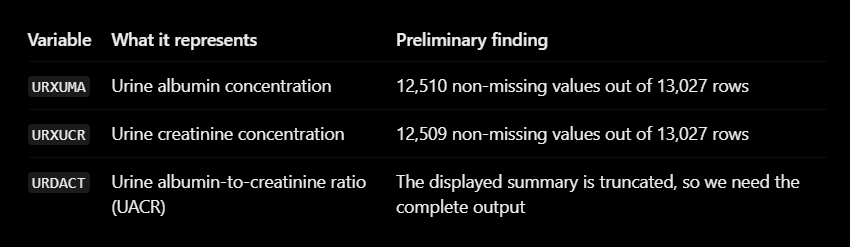